In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("diabetes.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Outcome"].value_counts())

Dataset Shape: (768, 9)

First 5 Rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-

Zero Values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


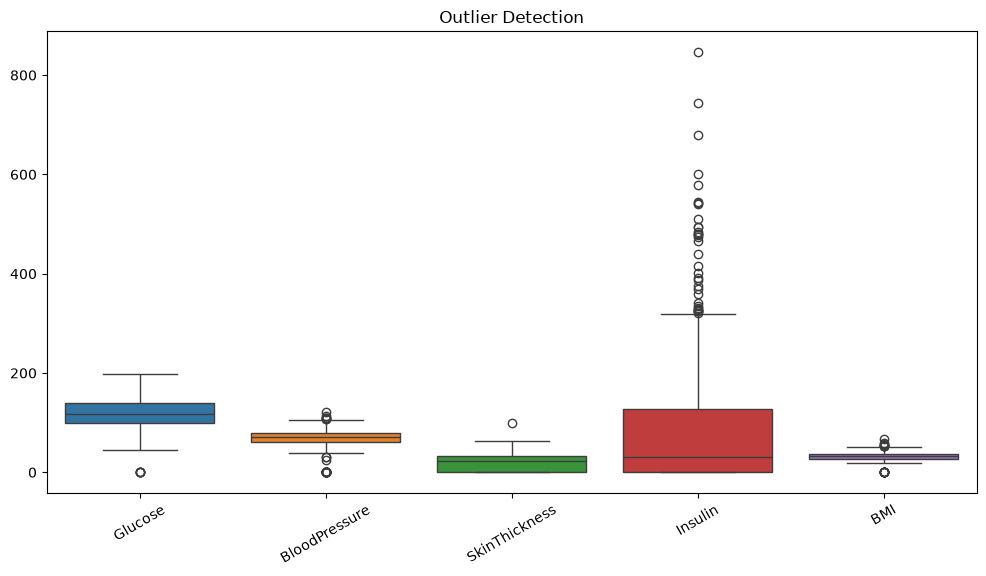

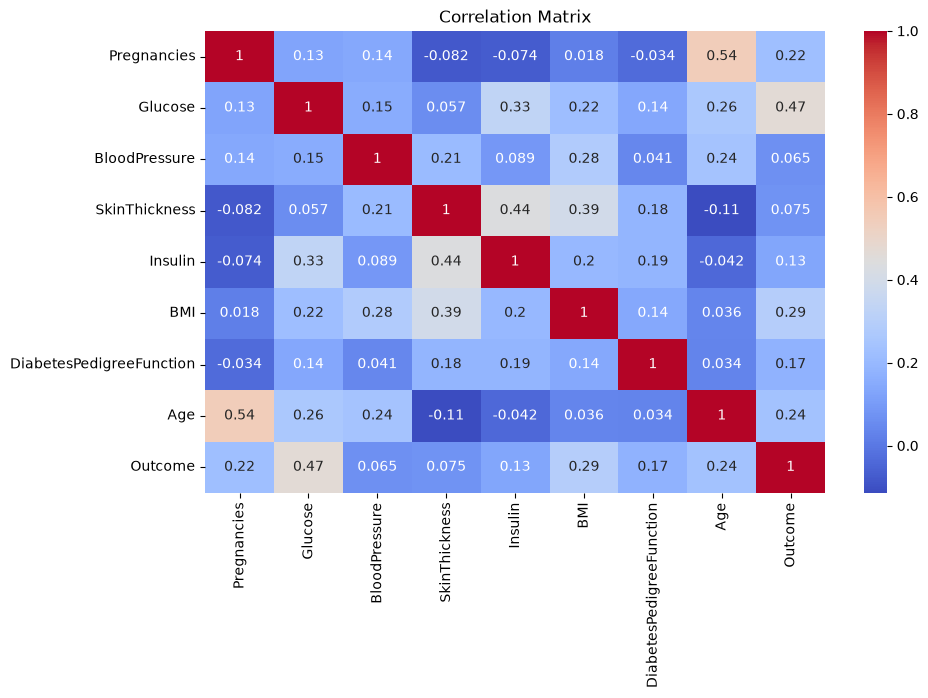

In [18]:

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Zero Values:")
print((df[zero_columns] == 0).sum())

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[zero_columns])

plt.title("Outlier Detection")
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X = X.copy()

X[zero_columns] = X[zero_columns].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))


Accuracy: 0.7077922077922078

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



In [20]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

results = []

for name, model in models.items():

    model_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    model_pipeline.fit(X_train, y_train)

    y_pred = model_pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score
                KNN     0.753      0.660   0.611     0.635
      Random Forest     0.747      0.660   0.574     0.614
Logistic Regression     0.708      0.600   0.500     0.545
      Decision Tree     0.682      0.553   0.481     0.515


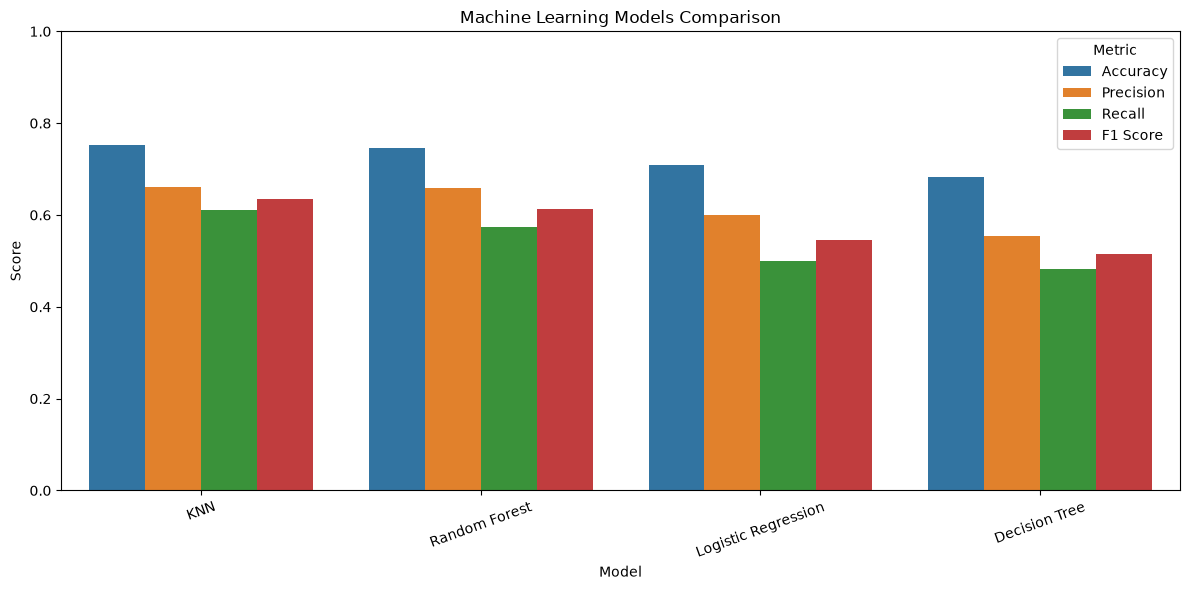

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Models Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [22]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Mean Score": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std()
    ]
})

print(cv_summary.round(3).to_string(index=False))

   Metric  Mean Score   Std
 Accuracy       0.772 0.017
Precision       0.726 0.062
   Recall       0.571 0.047
       F1       0.636 0.021


In [23]:
from sklearn.metrics import accuracy_score

models_check = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

overfitting_results = []

for name, model in models_check.items():

    model_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    model_pipeline.fit(X_train, y_train)

    train_predictions = model_pipeline.predict(X_train)
    test_predictions = model_pipeline.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_predictions)
    test_accuracy = accuracy_score(y_test, test_predictions)

    overfitting_results.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Difference": train_accuracy - test_accuracy
    })

overfitting_df = pd.DataFrame(overfitting_results)

print(overfitting_df.round(3).to_string(index=False))

              Model  Training Accuracy  Testing Accuracy  Difference
Logistic Regression              0.796             0.708       0.089
      Random Forest              1.000             0.747       0.253
                KNN              0.829             0.753       0.076
      Decision Tree              1.000             0.682       0.318


In [24]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", round(grid_search.best_score_, 3))

best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, tuned_predictions))
print("Test Precision:", precision_score(y_test, tuned_predictions))
print("Test Recall:", recall_score(y_test, tuned_predictions))
print("Test F1:", f1_score(y_test, tuned_predictions))

Best Parameters: {'model__max_depth': 15, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV F1 Score: 0.663
Test Accuracy: 0.7662337662337663
Test Precision: 0.6956521739130435
Test Recall: 0.5925925925925926
Test F1: 0.64


                 Feature  Importance
                 Glucose      0.2764
                     BMI      0.1643
DiabetesPedigreeFunction      0.1252
                     Age      0.1126
                 Insulin      0.0889
           BloodPressure      0.0810
             Pregnancies      0.0795
           SkinThickness      0.0721


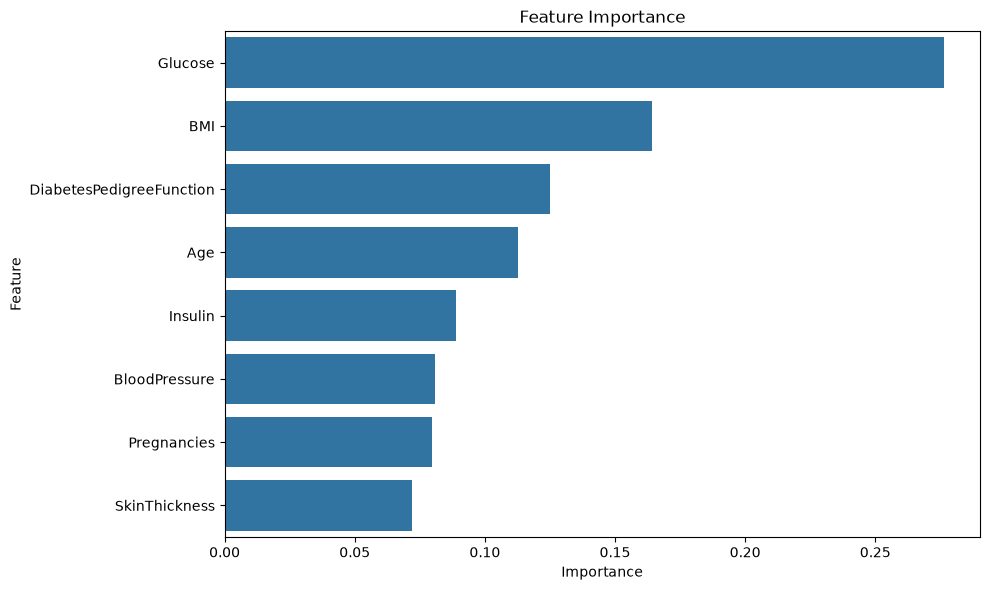

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rf_model = best_model.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.round(4).to_string(index=False))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.tight_layout()
plt.show()

In [26]:
import joblib

joblib.dump(best_model, "diabetes_model.pkl")

print("Model saved successfully!")

Model saved successfully!
